# Multi-Layer Perceptron

The perceptron is a feed-forward network based on a threshold transfer function. It is the simplest type of artificial neural networks and can only classify linearly separable cases with a binary target (1, 0). 

Because the perceptron is a linear classifier, if the cases are not linearly separable the learning process will never reach a point where all the cases are classified properly( eg. XOR problem).

A multi-layer perceptron (MLP) has the same structure of the perceptron model with one or more hidden layers. The backpropagation algorithm consists of two phases: the <b>forward phase</b> where the activations are propagated from the input to the output layer, and the <b>backward phase</b>, where the error between the observed actual and the requested nominal value in the output layer is propagated backwards in order to modify the weights and bias values.

In this lab, we will use the Titanic Dataset. 

The training will be used to build your machine learning model. For the training set, we provide the outcome (also known as the “ground truth”) for each passenger. The model will be based on "features" like passengers’ gender and class. 

The test will be used to see how well your model performs on unseen data. For each passenger in the test set, use the model you trained to predict whether or not they survived the sinking of the Titanic.

In [1]:
import numpy as np 
np.random.seed(10)
import pandas as pd 
import matplotlib.pyplot as plt
import seaborn as sns

%matplotlib inline

from sklearn import metrics
from sklearn.metrics import accuracy_score, confusion_matrix
from sklearn.model_selection import train_test_split
      
data = pd.read_csv('train.csv')
data.head(4)

,PassengerId,Survived,Pclass,Name,Sex,Age,SibSp,Parch,Ticket,Fare,Cabin,Embarked
0,1,0,3,"Braund, Mr. Owen Harris",male,22.0,1,0,A/5 21171,7.2500,NaN,S
1,2,1,1,"Cumings, Mrs. John Bradley (Florence Briggs Th...",female,38.0,1,0,PC 17599,71.2833,C85,C
2,3,1,3,"Heikkinen, Miss. Laina",female,26.0,0,0,STON/O2. 3101282,7.9250,NaN,S
3,4,1,1,"Futrelle, Mrs. Jacques Heath (Lily May Peel)",female,35.0,1,0,113803,53.1000,C123,S


In [2]:
# We define a dictionary to transform the 0,1 values in the labels to a String that defines the fate of the passenger
dict_live = { 
    0 : 'Perished',
    1 : 'Survived'
}

# We define a dictionary to binarize the sex
dict_sex = {
    'male' : 0,
    'female' : 1
}

# We apply the dictionary using a lambda function and the pandas .apply() module
data['Bsex'] = data['Sex'].apply(lambda x : dict_sex[x])


# Now the features are a 2 column matrix whose entries are the Class (1,2,3) and the gender (0,1) of the passengers
features = data[['Pclass', 'Bsex']].to_numpy()
labels = data['Survived'].to_numpy()

## Perceptron
   #### 1) From scratch 

We will first implement a model using the simple Perceptron. 
We'll start by defining the activation functions we may use.

In [3]:
def sigmoid_act(x, der=False):
    import numpy as np
    
    if (der==True) : #derivative of the sigmoid
        f = 1/(1+ np.exp(- x))*(1-1/(1+ np.exp(- x)))
    else : # sigmoid
        f = 1/(1+ np.exp(- x))
    
    return f

# We may employ the Rectifier Linear Unit (ReLU)
def ReLU_act(x, der=False):
    import numpy as np
    
    if (der == True): # the derivative of the ReLU is the Heaviside Theta
        f = np.heaviside(x, 1)
    else :
        f = np.maximum(x, 0)
    
    return f

Now we are ready to define the perceptron 

In [4]:
def perceptron(X, act='Sigmoid'): 
    import numpy as np
    
    shapes = X.shape # Pick the number of (rows, columns)!
    n= shapes[0]+shapes[1]
    # Generating random weights and bias
    w = 2*np.random.random(shapes) - 0.5 # We want w to be between -1 and 1
    b = np.random.random(1)
    
    # Initialize the function
    f = b[0]
    for i in range(0, X.shape[0]-1) : # run over column elements
        for j in range(0, X.shape[1]-1) : # run over rows elements
            f += w[i, j]*X[i,j]/n
    # Pass it to the activation function and return it as an output
    if act == 'Sigmoid':
        output = sigmoid_act(f)
    else :
        output = ReLU_act(f)
        
    return output

An example of an output of the Perceptron

In [5]:
print('Output with sigmoid activator: ', perceptron(features, act='Sigmoid'))
print('Output with ReLU activator: ', perceptron(features))

Output with sigmoid activator:  0.8536800619299082
Output with ReLU activator:  0.8515450291672023


   #### 2) Implemented algorithm in Sklearn 

In [6]:
from sklearn.linear_model import Perceptron
clf = Perceptron(random_state=0)
clf.fit(features, labels)
clf.score(features, labels)

0.7508417508417509

## Multi-Layer Perceptron

In [7]:
from sklearn.model_selection import train_test_split

X_train, X_test, Y_train, Y_test = train_test_split(features, labels, test_size=0.30)

print('Training records:',Y_train.size)
print('Test records:',Y_test.size)

Training records: 623
Test records: 268


We will build a Multi-layer Perceptron from scratch . We set the number of hidden layers to 2 and we use 4 neurons in each layer and we randomly initialize the weights. When defining the algorithm we'll follow the same steps discussed in the course :
<ol>
    <li>Feed forward</li>
    <li>Compute the output layer's error</li>
    <li>Backpropagate</li>
    <li>Gradient descent</li>
    <li>Computation of the loss function</li>
</ol>
Below is the implementation of the algorithm :

In [8]:
# Set up the number of perceptron per each layer:
p=4 # Layer 1
q=4 # Layer 2

# Set up the Learning rate
eta =  1/623


# 0: Random initialize the relevant data 
w1 = 2*np.random.rand(p , X_train.shape[1]) - 0.5 # Layer 1
b1 = np.random.rand(p)

w2 = 2*np.random.rand(q , p) - 0.5  # Layer 2
b2 = np.random.rand(q)

wOut = 2*np.random.rand(q) - 0.5  # Output Layer
bOut = np.random.rand(1)

mu = []
vec_y = []

# Start looping over the passengers, i.e. over I.
for I in range(0, X_train.shape[0]): #loop in all the passengers:
    
    # 1: input the data 
    x = X_train[I]
    
    
    # 2: Start the algorithm
    
    # 2.1: Feed forward
    z1 = ReLU_act(np.dot(w1, x) + b1) # output layer 1 
    z2 = ReLU_act(np.dot(w2, z1) + b2) # output layer 2
    y = sigmoid_act(np.dot(wOut, z2) + bOut) # Output of the Output layer
    
    #2.2: Compute the output layer's error
    delta_Out =  (y-Y_train[I]) * sigmoid_act(y, der=True)
    
    #2.3: Backpropagate
    delta_2 = delta_Out * wOut * ReLU_act(z2, der=True) # Second Layer Error
    delta_1 = np.dot(delta_2, w2) * ReLU_act(z1, der=True) # First Layer Error
    
    # 3: Gradient descent 
    wOut = wOut - eta*delta_Out*z2  # Outer Layer
    bOut = bOut - eta*delta_Out
    w2 = w2 - eta*np.kron(delta_2, z1).reshape(q,p) # Hidden Layer 2
    b2 = b2 - eta*delta_2
    
    w1 = w1 - eta*np.kron(delta_1, x).reshape(p, x.shape[0]) # Hidden Layer 1
    b1 = b1 - eta*delta_1
    
    # 4. Computation of the loss function
    mu.append((1/2)*(y-Y_train[I])**2)
    vec_y.append(y[0])


### Compute Predictions

Now we will use the trained parameters {w},{b} to actually get the predictions.

In [9]:
def ANN_pred(X_test, w1, b1, w2, b2, wOut, bOut, mu):
    import numpy as np
    
    pred = []
    
    for I in range(0, X_test.shape[0]): #loop in all the passengers
        # 1: input the data 
        x = X_test[I]
        
        # 2.1: Feed forward
        z1 = ReLU_act(np.dot(w1, x) + b1) # output layer 1 
        z2 = ReLU_act(np.dot(w2, z1) + b2) # output layer 2
        y = sigmoid_act(np.dot(wOut, z2) + bOut)  # Output of the Output layer
        
        # Append the prediction;
        # We now need a binary classifier; we this apply an Heaviside Theta and we set to 0.5 the threshold
        # if y < 0.5 the output is zero, otherwise is 1
        pred.append( np.heaviside(y - 0.5, 1)[0] )
    
    
    return np.array(pred);

In [10]:
# model evaluation
predictions = ANN_pred(X_test, w1, b1, w2, b2, wOut, bOut, mu)
accuracy_score(Y_test, predictions)

0.6529850746268657

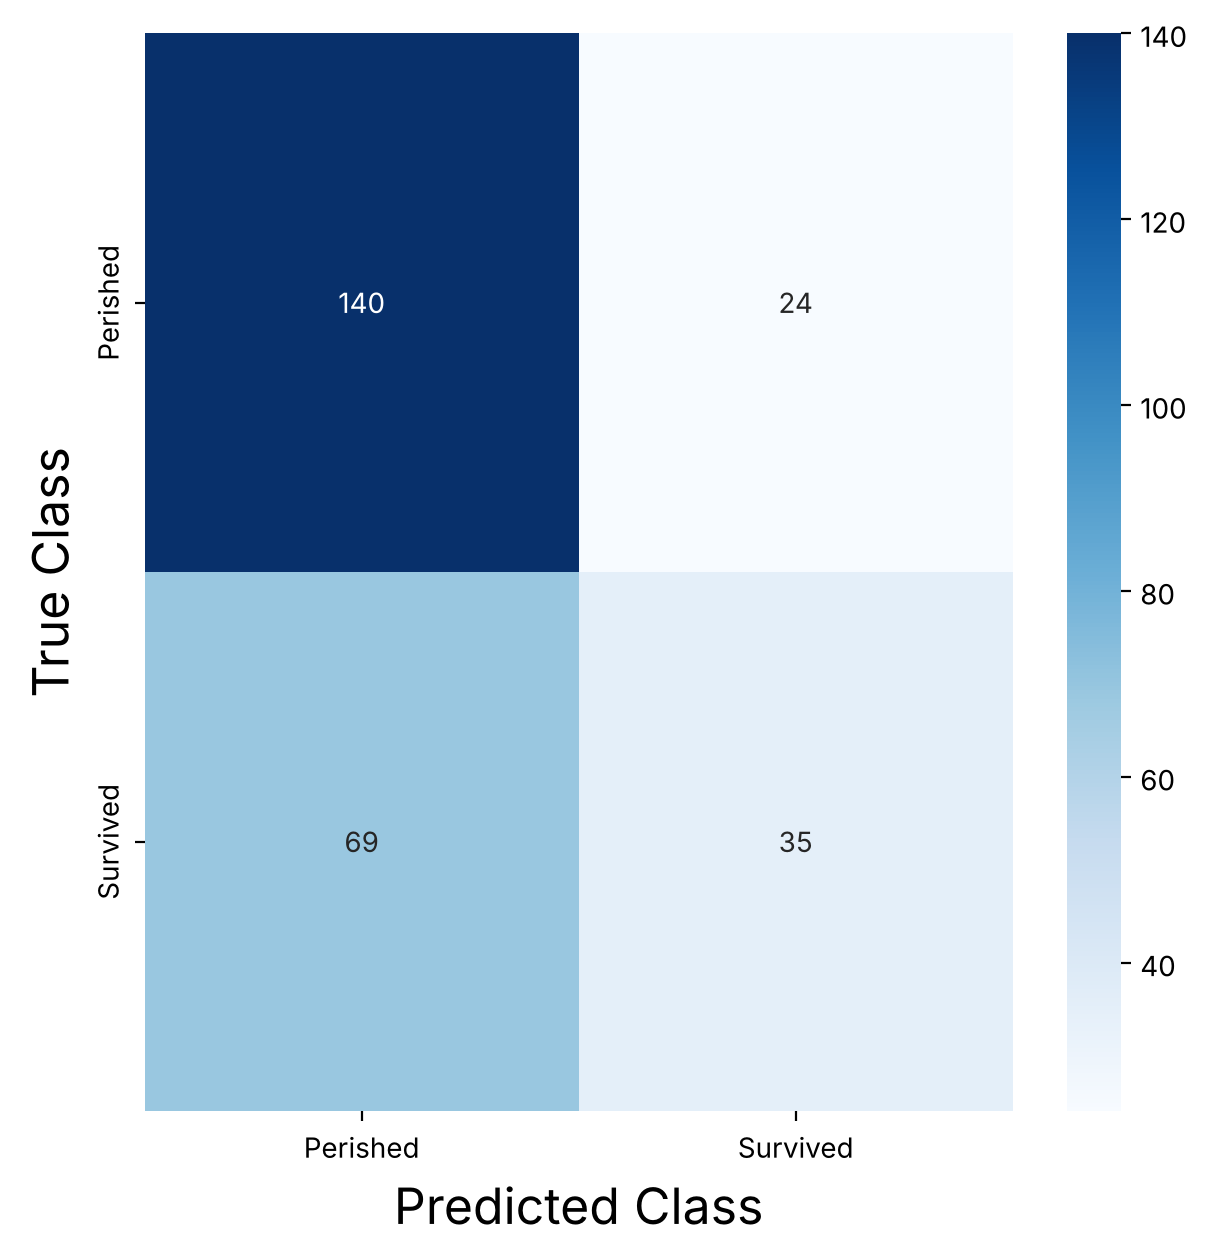

In [11]:

# Plot the confusion matrix
cm = confusion_matrix(Y_test, predictions)

df_cm = pd.DataFrame(cm, index = [dict_live[i] for i in range(0,2)], columns = [dict_live[i] for i in range(0,2)])
plt.figure(figsize = (7,7))
sns.heatmap(df_cm, annot=True, cmap=plt.cm.Blues, fmt='g')
plt.xlabel("Predicted Class", fontsize=18)
plt.ylabel("True Class", fontsize=18)
plt.show()

## Activities

#### Remarques sur les résultats ci-dessus

- **Perceptron sklearn** : 75.1 % d'accuracy sur le train avec (`Pclass`, `Bsex`).
- **MLP from scratch** : seulement **65.3 %** sur le test, et la matrice de confusion montre un rappel très faible (peu de survivants retrouvés). En regardant ses prédictions par profil, on constate qu'il prédit « survivant » pour **toute la 1ʳᵉ classe** et « mort » pour **toutes les autres**, sans tenir compte du **sexe**, pourtant le facteur le plus déterminant. Raisons : (1) **une seule passe** sur 623 exemples (1 époque), (2) un taux d'apprentissage minuscule (`eta = 1/623 ≈ 0.0016`) donc les poids bougent très peu depuis leur initialisation aléatoire, (3) le gradient de la couche de sortie est calculé avec la dérivée de la sigmoïde évaluée en `y` (`σ'(y)`) plutôt qu'avec `y(1−y)`, ce qui en donne une approximation moins précise. Avec plusieurs époques et un `eta` plus grand, il progresserait nettement (voir `MLPClassifier` plus bas).
- La fonction `perceptron()` de la cellule 9 n'**entraîne** rien : elle ne fait qu'une propagation avant avec des poids aléatoires (d'où une sortie ≈ 0.85 sans signification).

### Activité 1 — Prédictions sur `test.csv`

`test.csv` ne contient **pas** la colonne `Survived` (c'est le jeu de test Kaggle) : on ne peut donc pas calculer d'accuracy dessus, mais on peut produire les prédictions et les enregistrer au format de soumission. On applique exactement le même prétraitement que pour `train.csv` (`Pclass`, `Bsex`) avec le réseau MLP *from scratch* entraîné plus haut.

In [12]:
test = pd.read_csv('test.csv')
test['Bsex'] = test['Sex'].apply(lambda x: dict_sex[x])
X_kaggle = test[['Pclass', 'Bsex']].to_numpy()

pred_test = ANN_pred(X_kaggle, w1, b1, w2, b2, wOut, bOut, mu).astype(int)
sub = pd.DataFrame({'PassengerId': test['PassengerId'], 'Survived': pred_test})
sub.to_csv('predictions_MLP_scratch.csv', index=False)
print(sub.shape)
print(sub['Survived'].map(dict_live).value_counts())
sub.head(8)

(418, 2)
Survived
Perished    311
Survived    107
Name: count, dtype: int64


,PassengerId,Survived
0,892,0
1,893,0
2,894,0
3,895,0
4,896,0
5,897,0
6,898,0
7,899,0


**Remarque** : le réseau prédit 107 survivants sur 418 (≈ 26 %), contre ≈ 38 % de survivants dans `train.csv`. Cela confirme le constat précédent : ce modèle sous-estime les survivants (il ignore le sexe et ne retient que la 1ʳᵉ classe). Les prédictions du meilleur modèle sont données en fin de notebook. Les fichiers `predictions_MLP_scratch.csv` et `predictions_MLPClassifier.csv` sont au format Kaggle (`PassengerId`, `Survived`).

### Activité 2 — `sklearn.neural_network.MLPClassifier`

On utilise la même séparation train/test que plus haut (mêmes `X_train, X_test, Y_train, Y_test`) et on fait varier les hyper-paramètres un par un : architecture, fonction d'activation, solveur, `learning_rate_init`, `max_iter`, régularisation `alpha`.

In [13]:
import warnings
from sklearn.neural_network import MLPClassifier
from sklearn.exceptions import ConvergenceWarning
warnings.filterwarnings('ignore', category=ConvergenceWarning)

def run(name, X_tr, X_te, y_tr, y_te, **kw):
    m = MLPClassifier(random_state=0, **kw).fit(X_tr, y_tr)
    return dict(config=name, train=m.score(X_tr, y_tr), test=m.score(X_te, y_te), iters=m.n_iter_, loss=m.loss_)

exps = [
 ('défaut (100,) relu adam',            dict()),
 ('(4,4) relu adam [comme scratch]',    dict(hidden_layer_sizes=(4, 4))),
 ('(64,12) relu adam',                  dict(hidden_layer_sizes=(64, 12))),
 ('(128,64,32) relu adam',              dict(hidden_layer_sizes=(128, 64, 32))),
 ('(64,12) tanh',                       dict(hidden_layer_sizes=(64, 12), activation='tanh')),
 ('(64,12) logistic',                   dict(hidden_layer_sizes=(64, 12), activation='logistic')),
 ('(64,12) identity',                   dict(hidden_layer_sizes=(64, 12), activation='identity')),
 ('(64,12) solver=sgd',                 dict(hidden_layer_sizes=(64, 12), solver='sgd')),
 ('(64,12) solver=lbfgs',               dict(hidden_layer_sizes=(64, 12), solver='lbfgs')),
 ('(64,12) lr_init=0.0001',             dict(hidden_layer_sizes=(64, 12), learning_rate_init=1e-4)),
 ('(64,12) lr_init=0.01',               dict(hidden_layer_sizes=(64, 12), learning_rate_init=1e-2)),
 ('(64,12) lr_init=0.1',                dict(hidden_layer_sizes=(64, 12), learning_rate_init=1e-1)),
 ('(64,12) max_iter=20',                dict(hidden_layer_sizes=(64, 12), max_iter=20)),
 ('(64,12) max_iter=1000',              dict(hidden_layer_sizes=(64, 12), max_iter=1000)),
 ('(64,12) alpha=0.1 (L2)',             dict(hidden_layer_sizes=(64, 12), alpha=0.1)),
 ('(64,12) early_stopping',             dict(hidden_layer_sizes=(64, 12), early_stopping=True)),
]
out = pd.DataFrame([run(n, X_train, X_test, Y_train, Y_test, **kw) for n, kw in exps]).set_index('config')
out[['train', 'test']] *= 100
display(out.round(3))

,train,test,iters,loss
config,,,,
"défaut (100,) relu adam",78.010,80.224,140,0.460
"(4,4) relu adam [comme scratch]",78.010,80.224,200,0.478
"(64,12) relu adam",78.652,78.731,170,0.455
"(128,64,32) relu adam",78.010,80.224,47,0.458
"(64,12) tanh",78.010,80.224,94,0.458
"(64,12) logistic",78.010,80.224,200,0.463
"(64,12) identity",78.010,80.224,48,0.467
"(64,12) solver=sgd",78.010,80.224,200,0.478
"(64,12) solver=lbfgs",78.652,78.731,54,0.454


Avec seulement 2 variables (`Pclass`, `Bsex`) il n'existe que **6 profils de passagers** différents : le réseau ne peut donc pas faire mieux qu'un plafond théorique. On le calcule, puis on enrichit les variables pour voir si un réseau plus gros sert réellement à quelque chose.

In [14]:
# Plafond théorique avec (Pclass, Sexe) : on prédit la classe majoritaire de chaque profil
prof = data.groupby(['Pclass', 'Bsex'])['Survived'].agg(['mean', 'count']).round(3)
display(prof)
ceiling = (data.groupby(['Pclass', 'Bsex'])['Survived'].apply(lambda s: max(s.mean(), 1 - s.mean()) * len(s)).sum()) / len(data)
print('Accuracy maximale atteignable avec (Pclass, Sexe) seuls : %.3f' % ceiling)

mean  count
Pclass Bsex              
1      0     0.369    122
       1     0.968     94
2      0     0.157    108
       1     0.921     76
3      0     0.135    347
       1     0.500    144

Accuracy maximale atteignable avec (Pclass, Sexe) seuls : 0.787


**Jeu de variables enrichi** : on ajoute `Age` (imputé par la médiane), `Fare`, `SibSp`, `Parch`, `Embarked` (one-hot) et on **standardise** (indispensable pour un réseau de neurones). L'imputation et la standardisation sont ajustées uniquement sur le train (pipeline) pour éviter toute fuite d'information.

In [15]:
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.pipeline import make_pipeline

num = ['Pclass', 'Age', 'SibSp', 'Parch', 'Fare']
cat = ['Sex', 'Embarked']
prep = ColumnTransformer([
    ('num', make_pipeline(SimpleImputer(strategy='median'), StandardScaler()), num),
    ('cat', make_pipeline(SimpleImputer(strategy='most_frequent'), OneHotEncoder(handle_unknown='ignore')), cat)])

Xf = data[num + cat]
yf = data['Survived']
Xf_tr, Xf_te, yf_tr, yf_te = train_test_split(Xf, yf, test_size=0.30, random_state=10, stratify=yf)

def run_full(name, **kw):
    pipe = make_pipeline(prep, MLPClassifier(random_state=0, **kw)).fit(Xf_tr, yf_tr)
    return dict(config=name, train=pipe.score(Xf_tr, yf_tr)*100, test=pipe.score(Xf_te, yf_te)*100)

exps2 = [
 ('(4,4) relu',              dict(hidden_layer_sizes=(4, 4), max_iter=1000)),
 ('(64,12) relu',            dict(hidden_layer_sizes=(64, 12), max_iter=1000)),
 ('(64,12) tanh',            dict(hidden_layer_sizes=(64, 12), activation='tanh', max_iter=1000)),
 ('(64,12) relu alpha=0.1',  dict(hidden_layer_sizes=(64, 12), alpha=0.1, max_iter=1000)),
 ('(16,) relu alpha=0.1',    dict(hidden_layer_sizes=(16,), alpha=0.1, max_iter=1000)),
 ('(128,64,32) relu',        dict(hidden_layer_sizes=(128, 64, 32), max_iter=1000)),
 ('(32,16) relu early_stopping', dict(hidden_layer_sizes=(32, 16), early_stopping=True, max_iter=1000)),
 ('(32,16) lbfgs alpha=1',   dict(hidden_layer_sizes=(32, 16), solver='lbfgs', alpha=1.0, max_iter=1000)),
]
out2 = pd.DataFrame([run_full(n, **kw) for n, kw in exps2]).set_index('config')
display(out2.round(2))

,train,test
config,,
"(4,4) relu",82.83,79.10
"(64,12) relu",86.36,82.84
"(64,12) tanh",85.71,82.46
"(64,12) relu alpha=0.1",85.39,82.84
"(16,) relu alpha=0.1",83.79,83.58
"(128,64,32) relu",89.09,79.85
"(32,16) relu early_stopping",79.29,73.13
"(32,16) lbfgs alpha=1",90.53,79.85


#### Remarques

**1. Avec (`Pclass`, `Sexe`) seulement** : toutes les configurations donnent pratiquement le **même résultat** (≈ 78–79 % en train, 79–80 % en test), quelle que soit l'architecture (de (4,4) à (128,64,32)), l'activation (même `identity`, c'est-à-dire un modèle linéaire), le solveur, le taux d'apprentissage ou `max_iter`. L'explication est que les données ne contiennent que **6 profils différents** (3 classes × 2 sexes) : le meilleur classifieur possible (prédire la classe majoritaire de chaque profil) plafonne à **78.7 %**. Il est inutile d'ajouter des neurones : le goulot d'étranglement est l'information, pas le modèle. Les écarts de 1.5 point en test correspondent à 4 passagers sur 268, du bruit de séparation. Seules différences visibles : un `max_iter` trop faible (20) ou un `learning_rate_init` trop petit (1e-4) donnent une loss plus élevée (0.51), car le réseau n'a pas fini d'apprendre ; `lr=0.1` converge très vite (28 itérations).

**2. Avec le jeu enrichi** (âge, tarif, SibSp, Parch, port d'embarquement + standardisation) : l'accuracy test monte à **≈ 83–84 %** (+4 points) et l'architecture compte enfin :
- les **gros réseaux surapprennent** : (128,64,32) → 89 % train mais 79.9 % test ; `lbfgs` avec 32-16 neurones → 90.5 % train / 79.9 % test ;
- un **petit réseau régularisé** `(16,)`, `alpha=0.1` est le meilleur compromis (83.8 % train / **83.6 %** test, aucun écart) ;
- `relu` ≈ `tanh` ; une pénalisation L2 (`alpha`) réduit l'écart train/test ;
- `early_stopping` avec (32,16) sous-apprend (73 % en test) : il garde 10 % des données pour la validation et arrête trop tôt.

**3. Bonnes pratiques à retenir** : standardiser les variables, ne pas utiliser un réseau plus gros que nécessaire sur ~900 exemples, régler `alpha` / `early_stopping` pour contrôler le surapprentissage, et confirmer le choix par validation croisée (ici un seul découpage de 268 exemples, donc les différences < 2 points ne sont pas significatives).

### Activité 3 — Métriques d'évaluation

On compare : (a) le MLP *from scratch*, (b) `MLPClassifier` sur (`Pclass`, `Bsex`) et (c) `MLPClassifier` sur le jeu enrichi. Classe positive = `Survived`.

,accuracy,précision,rappel,F1,AUC
modèle,,,,,
"(a) MLP scratch (Pclass,Sexe)",0.653,0.593,0.337,0.429,NaN
"(b) MLPClassifier (Pclass,Sexe)",0.787,0.961,0.471,0.632,0.841
(c) MLPClassifier (features+),0.836,0.831,0.718,0.771,0.891


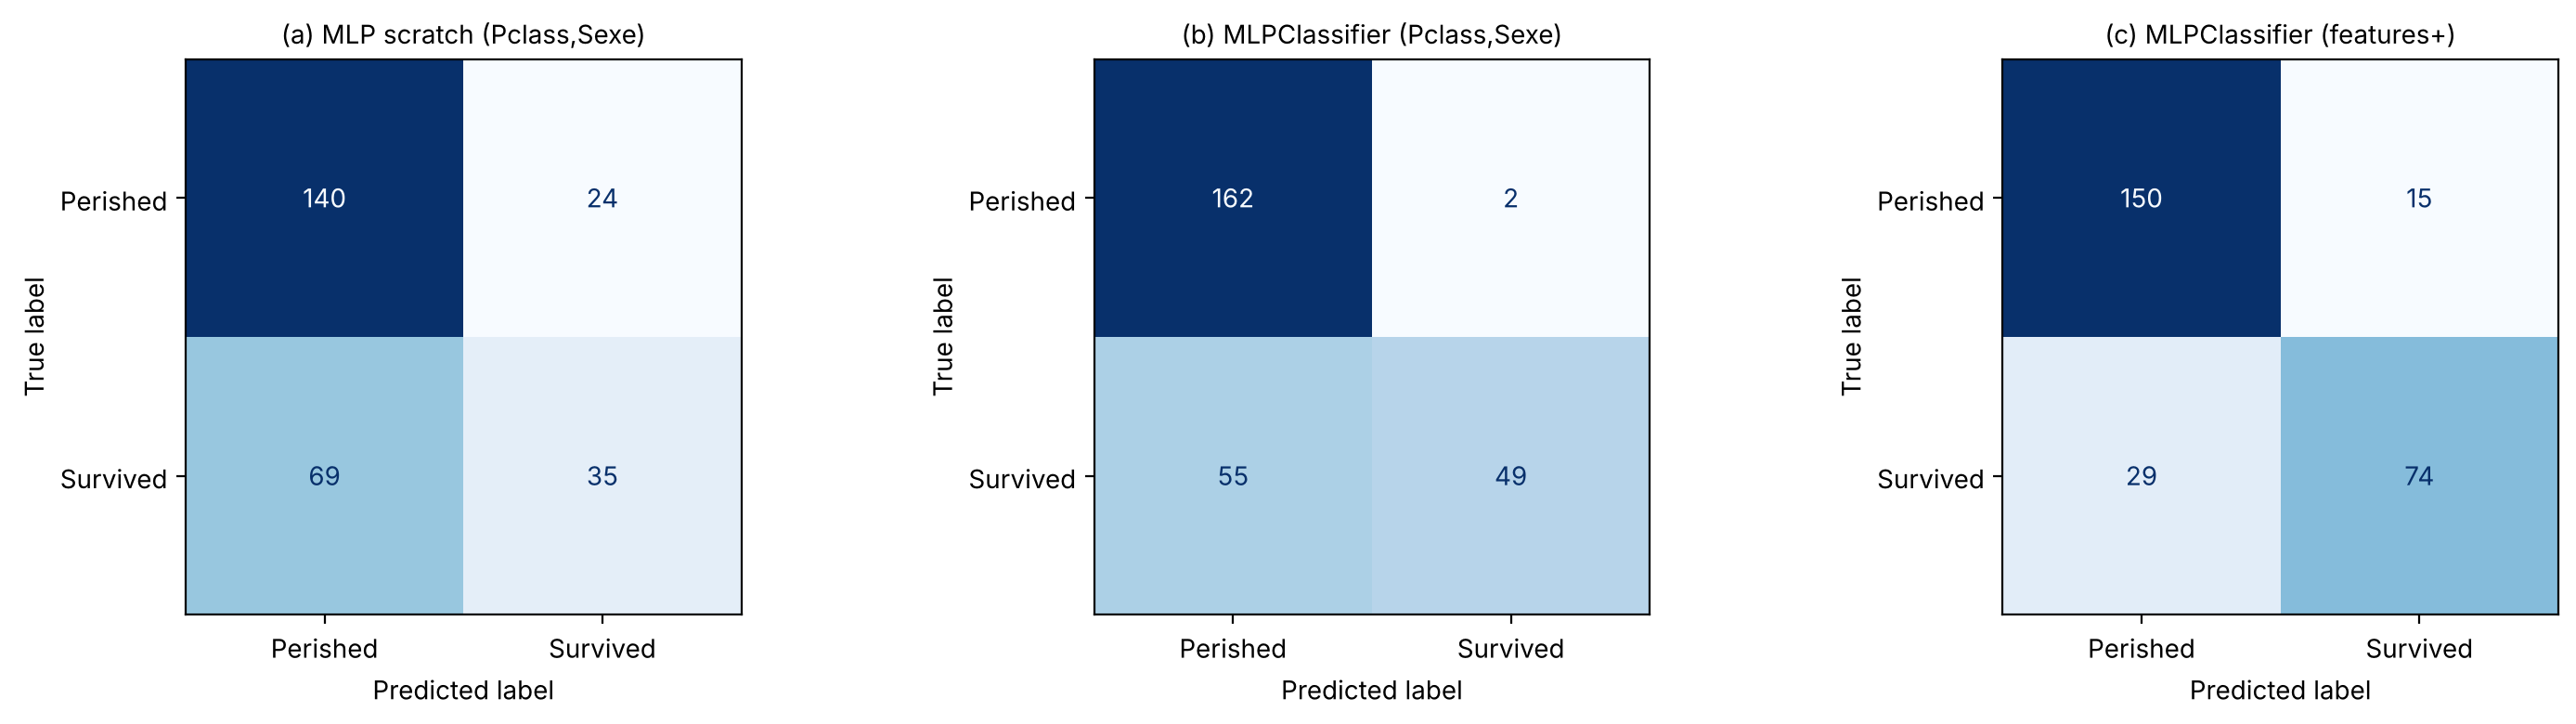

              precision    recall  f1-score   support

    Perished       0.84      0.91      0.87       165
    Survived       0.83      0.72      0.77       103

    accuracy                           0.84       268
   macro avg       0.83      0.81      0.82       268
weighted avg       0.84      0.84      0.83       268



In [16]:
from sklearn.metrics import (classification_report, precision_score, recall_score, f1_score,
                             roc_auc_score, ConfusionMatrixDisplay)

m_b = MLPClassifier(hidden_layer_sizes=(64, 12), random_state=0, max_iter=1000).fit(X_train, Y_train)
m_c = make_pipeline(prep, MLPClassifier(hidden_layer_sizes=(16,), alpha=0.1, random_state=0, max_iter=1000)).fit(Xf_tr, yf_tr)

cands = {
  '(a) MLP scratch (Pclass,Sexe)'    : (Y_test, predictions, None),
  '(b) MLPClassifier (Pclass,Sexe)'  : (Y_test, m_b.predict(X_test), m_b.predict_proba(X_test)[:, 1]),
  '(c) MLPClassifier (features+)'    : (yf_te, m_c.predict(Xf_te), m_c.predict_proba(Xf_te)[:, 1]),
}
rows = []
for k, (yt, yp, ypr) in cands.items():
    rows.append(dict(modèle=k, accuracy=accuracy_score(yt, yp), précision=precision_score(yt, yp, zero_division=0),
                     rappel=recall_score(yt, yp), F1=f1_score(yt, yp),
                     AUC=roc_auc_score(yt, ypr) if ypr is not None else np.nan))
display(pd.DataFrame(rows).set_index('modèle').round(3))

fig, ax = plt.subplots(1, 3, figsize=(15, 4))
for a_, (k, (yt, yp, _)) in zip(ax, cands.items()):
    ConfusionMatrixDisplay.from_predictions(yt, yp, display_labels=['Perished', 'Survived'], cmap='Blues', ax=a_, colorbar=False)
    a_.set_title(k, fontsize=10)
plt.tight_layout(); plt.show()
print(classification_report(yf_te, m_c.predict(Xf_te), target_names=['Perished', 'Survived']))

**Prédictions finales sur `test.csv` avec le meilleur modèle (jeu enrichi) :**

In [17]:
final = make_pipeline(prep, MLPClassifier(hidden_layer_sizes=(16,), alpha=0.1, random_state=0, max_iter=1000)).fit(Xf, yf)
pred_final = final.predict(test[num + cat])
sub2 = pd.DataFrame({'PassengerId': test['PassengerId'], 'Survived': pred_final})
sub2.to_csv('predictions_MLPClassifier.csv', index=False)
print(sub2['Survived'].map(dict_live).value_counts())

Survived
Perished    281
Survived    137
Name: count, dtype: int64


#### Interprétation

| Modèle | Constat |
|---|---|
| **(a) MLP from scratch** | Accuracy 65 %, rappel de seulement 0.34 : il rate 2 survivants sur 3 (il prédit « mort » dès qu'on n'est pas en 1ʳᵉ classe). |
| **(b) MLPClassifier (Pclass, Sexe)** | Accuracy 78.7 %, **précision 0.96** mais **rappel 0.47** : il ne prédit « survivant » que pour les femmes de 1ʳᵉ/2ᵉ classe (sûr à ~95 %), mais manque presque la moitié des survivants (notamment les femmes de 3ᵉ classe, qui survivent à 50 %). AUC 0.84. |
| **(c) MLPClassifier (variables enrichies)** | Accuracy **83.6 %**, précision 0.83, rappel 0.72, **F1 0.77**, AUC **0.89** : meilleur équilibre précision/rappel et meilleure capacité de classement. |

- L'**accuracy seule est trompeuse** : le jeu est déséquilibré (62 % de morts), un modèle qui prédit toujours « mort » obtiendrait déjà ≈ 62 %. C'est pourquoi on regarde aussi précision, rappel, F1 et AUC.
- Le modèle (c) est le meilleur sur toutes les métriques, ce qui montre que **l'enrichissement des variables a plus d'impact que la complexité du réseau**.
- ⚠️ Le modèle (c) utilise un découpage train/test **stratifié** différent (`random_state=10`, même proportion 70/30) de celui de (a) et (b) : la comparaison est indicative.
- `predictions_MLPClassifier.csv` contient les prédictions finales sur `test.csv` (modèle (c) ré-entraîné sur tout `train.csv`).